# Face Shape Classification

Classifying face shapes (heart, round, square) from a photo with an MLP, a CNN and transfer learning. The dataset is not included: see `data/README.md`.

## Task 3.1: Create an Image Dataset

### A: Dataset Creation

The dataset for my project was primarily constructed through extensive web scraping, and a bit of image generation. I began by collecting a large volume of images based on relevant search queries, aiming to capture as many results as possible to ensure variety. After the initial scraping phase, I performed a thorough filtering process, removing images that featured sketched or drawn overlays on the face, as well as those that weren’t clearly frontal-facing, to maintain consistency in facial orientation. Upon analyzing the gender distribution, I noticed a significant imbalance, with female images heavily outnumbering male ones. To address this, I sourced additional male images to improve dataset diversity and support fairer model training.


### B: Dataset Cleaning

The dataset cleaning and preparation process was essential to ensure consistency and quality across all images used in the project. The raw images were sourced from various web platforms and were found in multiple file formats, including .png, .jpeg, .bmp, .gif, .tiff, .webp, and .avif. As these formats can lead to compatibility issues or inconsistencies in machine learning workflows, a preprocessing script was implemented using the Python Imaging Library (PIL) to convert all supported files into high-quality .jpg format. Images already in .jpg format were copied directly, while unreadable or corrupted files were skipped with appropriate error handling to maintain pipeline stability.

After format standardization, an analysis of image resolutions was performed to detect irregularities. Images with resolutions below 128×128 pixels were flagged, as such dimensions are typically insufficient for deep learning tasks and can impact model performance.

To further standardize the dataset, a resizing method was applied to scale each image to 128×128 pixels while preserving the original aspect ratio. This was achieved through proportional resizing with padding, where the padding color was derived from the top-left pixel to ensure visual consistency. This approach prevented distortion that might otherwise occur with cropping or stretching.

For efficiency, image processing was parallelized using Python’s ThreadPoolExecutor, significantly reducing runtime. The images were organized into three categories (“Heart,” “Round,” and “Square”), with each set processed and stored in separate output directories.

Following the resizing procedure, a secondary resolution check was conducted to confirm that all images matched the intended dimensions. As a result, the dataset was standardized, balanced, and ready for training without requiring additional preprocessing, thereby enhancing the reliability and robustness of the training pipeline.

In [5]:
from PIL import Image
import os
import shutil
#### Dataset Conversion to .jpg format

##### Heart Folder

In [2]:
# Define your input and output directories
input_folder = "Dataset_Images/Generating images - extra/Heart"
output_folder = "Dataset_Images/Generating images - extra/Heart JPG"

# Create the output folder if it doesn't exist
os.makedirs(output_folder, exist_ok=True)

# Loop through all files in the input folder
for filename in os.listdir(input_folder):
    input_path = os.path.join(input_folder, filename)

    # Check if it's an image file
    if filename.lower().endswith(('.png', '.jpeg', '.bmp', '.gif', '.tiff', '.webp')):
        with Image.open(input_path) as img:
            # Convert and save as JPG
            output_path = os.path.join(output_folder, os.path.splitext(filename)[0] + ".jpg")
            img.convert("RGB").save(output_path, "JPEG", quality=95)
            print(f"Converted: {filename} -> {output_path}")

    elif filename.lower().endswith('.jpg'):  # If it's already a JPG, just copy it
        output_path = os.path.join(output_folder, filename)
        shutil.copy(input_path, output_path)
        print(f"Copied: {filename} -> {output_path}")

print("All images are now in JPG format in the new folder!")


##### Round Folder

In [3]:
from PIL import Image, UnidentifiedImageError

# Define your input and output directories
input_folder = 'Dataset_Images/Generating images - extra/Round'
output_folder = 'Dataset_Images/Generating images - extra/Round JPG'

# Create the output folder if it doesn't exist
os.makedirs(output_folder, exist_ok=True)

# Loop through all files in the input folder
for filename in os.listdir(input_folder):
    input_path = os.path.join(input_folder, filename)

    # Check if it's an image file
    if filename.lower().endswith(('.png', '.jpeg', '.bmp', '.gif', '.tiff', '.webp', '.avif')):
        try:
            with Image.open(input_path) as img:
                # Convert and save as JPG
                output_path = os.path.join(output_folder, os.path.splitext(filename)[0] + ".jpg")
                img.convert("RGB").save(output_path, "JPEG", quality=95)
                print(f"Converted: {filename} -> {output_path}")
        except UnidentifiedImageError:
            print(f"Cannot identify image file: {filename}")

    elif filename.lower().endswith('.jpg'):  # If it's already a JPG, just copy it
        output_path = os.path.join(output_folder, filename)
        shutil.copy(input_path, output_path)
        print(f"Copied: {filename} -> {output_path}")

print("All images are now in JPG format in the new folder!")

##### Square Folder

In [4]:
from PIL import Image, UnidentifiedImageError

# Define your input and output directories
input_folder = 'Dataset_Images/Generating images - extra/Square'
output_folder = 'Dataset_Images/Generating images - extra/Square JPG'

# Create the output folder if it doesn't exist
os.makedirs(output_folder, exist_ok=True)

# Loop through all files in the input folder
for filename in os.listdir(input_folder):
    input_path = os.path.join(input_folder, filename)

    # Check if it's an image file
    if filename.lower().endswith(('.png', '.jpeg', '.bmp', '.gif', '.tiff', '.webp', '.avif')):
        try:
            with Image.open(input_path) as img:
                # Convert and save as JPG
                output_path = os.path.join(output_folder, os.path.splitext(filename)[0] + ".jpg")
                img.convert("RGB").save(output_path, "JPEG", quality=95)
                print(f"Converted: {filename} -> {output_path}")
        except UnidentifiedImageError:
            print(f"Cannot identify image file: {filename}")

    elif filename.lower().endswith('.jpg'):  # If it's already a JPG, just copy it
        output_path = os.path.join(output_folder, filename)
        shutil.copy(input_path, output_path)
        print(f"Copied: {filename} -> {output_path}")

print("All images are now in JPG format in the new folder!")


#### Counting the number of images in each resolution


In [5]:
import os
from collections import defaultdict
from PIL import Image

# Function to count image resolutions
def count_image_resolutions(folder):
    resolution_count = defaultdict(int)

    for filename in os.listdir(folder):
        if filename.lower().endswith(('.png', '.jpeg', '.bmp', '.gif', '.tiff', '.webp', '.avif', '.jpg')):
            image_path = os.path.join(folder, filename)
            with Image.open(image_path) as img:
                resolution = img.size  # (width, height)
                resolution_count[resolution] += 1

    return resolution_count

# Define your input directories
folders = [
    "Dataset_Images/Generating images - extra/Heart JPG",
    "Dataset_Images/Generating images - extra/Round JPG",
    "Dataset_Images/Generating images - extra/Square JPG"
]

# Count and group the number of images in each resolution for each folder
grouped_resolutions = defaultdict(lambda: defaultdict(int))

for folder in folders:
    resolution_count = count_image_resolutions(folder)
    for resolution, count in resolution_count.items():
        grouped_resolutions[folder][resolution] = count

# Print the grouped resolution counts
for folder, resolutions in grouped_resolutions.items():
    print(f"Resolution counts for {folder}:")
    for resolution, count in resolutions.items():
        print(f"Resolution {resolution}: {count} images")
    print()

In [6]:
import os
from collections import defaultdict
from PIL import Image

# Function to count image resolutions and check if they are smaller than 164x256
def count_small_resolutions(folder, max_width, max_height):
    small_resolution_count = 0

    for filename in os.listdir(folder):
        if filename.lower().endswith(('.png', '.jpeg', '.bmp', '.gif', '.tiff', '.webp', '.avif', '.jpg')):
            image_path = os.path.join(folder, filename)
            with Image.open(image_path) as img:
                width, height = img.size
                if width < max_width and height < max_height:
                    small_resolution_count += 1

    return small_resolution_count

# Define your input directories
folders = [
    "Dataset_Images/Generating images - extra/Heart JPG",
    "Dataset_Images/Generating images - extra/Round JPG",
    "Dataset_Images/Generating images - extra/Square JPG"
]

# Define the maximum width and height
max_width = 128
max_height = 128

# Count and print the number of images with smaller resolution for each folder
for folder in folders:
    small_resolution_count = count_small_resolutions(folder, max_width, max_height)
    print(f"Number of images with resolution smaller than {max_width}x{max_height} in {folder}: {small_resolution_count}")

Number of images with resolution smaller than 128x128 in Dataset_Images/Generating images - extra/Heart JPG: 5
Number of images with resolution smaller than 128x128 in Dataset_Images/Generating images - extra/Round JPG: 7
Number of images with resolution smaller than 128x128 in Dataset_Images/Generating images - extra/Square JPG: 9


#### Resizing Images

In [7]:
import os
from PIL import Image

# Resize while maintaining aspect ratio with padding
def resize_with_padding(img, target_size, pad_color="auto"):
    old_size = img.size  # (width, height)
    ratio = min(target_size[0] / old_size[0], target_size[1] / old_size[1])
    new_size = (int(old_size[0] * ratio), int(old_size[1] * ratio))

    img = img.resize(new_size, Image.LANCZOS)

    if pad_color == "auto":
        pad_color = img.getpixel((0, 0))  # Use top-left pixel color

    new_img = Image.new("RGB", target_size, pad_color)
    new_img.paste(img, ((target_size[0] - new_size[0]) // 2, (target_size[1] - new_size[1]) // 2))

    return new_img

# Process images in parallel
from concurrent.futures import ThreadPoolExecutor

def process_folder_parallel(folder, output_folder, target_size):
    os.makedirs(output_folder, exist_ok=True)
    image_files = [f for f in os.listdir(folder) if f.lower().endswith(('.png', '.jpeg', '.bmp', '.gif', '.tiff', '.webp', '.avif', '.jpg'))]

    def process_image(filename):
        input_path = os.path.join(folder, filename)
        output_path = os.path.join(output_folder, filename)

        with Image.open(input_path) as img:
            img = img.convert("RGB")
            resized_img = resize_with_padding(img, target_size)
            resized_img.save(output_path, "JPEG", quality=95)

    with ThreadPoolExecutor() as executor:
        executor.map(process_image, image_files)

# Define dataset folders
folders = [
    'Dataset_Images/Generating images - extra/Heart JPG',
    'Dataset_Images/Generating images - extra/Round JPG',
    'Dataset_Images/Generating images - extra/Square JPG'
]

output_folders = [
    'Dataset_Images/Resized images_extra/Heart JPG',
    'Dataset_Images/Resized images_extra/Round JPG',
    'Dataset_Images/Resized images_extra/Square JPG'
]

target_size = (128, 128)

# Run processing
for folder, output_folder in zip(folders, output_folders):
    process_folder_parallel(folder, output_folder, target_size)

print("✅ All images resized successfully with aspect ratio maintained!")

✅ All images resized successfully with aspect ratio maintained!


#### Counting the number of images in each resolution


In [8]:
import os
from collections import defaultdict
from PIL import Image

# Function to count image resolutions
def count_image_resolutions(folder):
    resolution_count = defaultdict(int)

    for filename in os.listdir(folder):
        if filename.lower().endswith(('.png', '.jpeg', '.bmp', '.gif', '.tiff', '.webp', '.avif', '.jpg')):
            image_path = os.path.join(folder, filename)
            with Image.open(image_path) as img:
                resolution = img.size  # (width, height)
                resolution_count[resolution] += 1

    return resolution_count

# Define your input directories
folders = [
    "Dataset_Images/Resized images_extra/Heart JPG",
    "Dataset_Images/Resized images_extra/Round JPG",
    "Dataset_Images/Resized images_extra/Square JPG"
]

# Count and group the number of images in each resolution for each folder
grouped_resolutions = defaultdict(lambda: defaultdict(int))

for folder in folders:
    resolution_count = count_image_resolutions(folder)
    for resolution, count in resolution_count.items():
        grouped_resolutions[folder][resolution] = count

# Print the grouped resolution counts
for folder, resolutions in grouped_resolutions.items():
    print(f"Resolution counts for {folder}:")
    for resolution, count in resolutions.items():
        print(f"Resolution {resolution}: {count} images")
    print()

Resolution counts for Dataset_Images/Resized images_extra/Heart JPG:
Resolution (128, 128): 195 images

Resolution counts for Dataset_Images/Resized images_extra/Round JPG:
Resolution (128, 128): 180 images

Resolution counts for Dataset_Images/Resized images_extra/Square JPG:
Resolution (128, 128): 189 images



#### Downloading Images

In [9]:
import shutil

# Define the output directory
output_dir = "Dataset_Images/Resized_images_final"

# Create a zip file of the dataset
shutil.make_archive(output_dir, 'zip', output_dir)

print(f"Dataset zipped and ready for download: {output_dir}.zip")

Dataset zipped and ready for download: Dataset_Images/Resized_images_final.zip


### C: Final Dataset

The dataset is not published, because it consists of photographs of real people collected from the web. See `data/README.md` for its composition and how to rebuild it.

### D: Load and Split

In [7]:
# Import necessary libraries
import numpy as np
import cv2
import os
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from sklearn.preprocessing import LabelEncoder


In [1]:
import cv2
import numpy as np
import os

# Function to load images and labels correctly
def load_images_and_labels(folder, target_size=(128, 128)):
    images = []
    labels = []

    for label in sorted(os.listdir(folder)):  # Sort labels for consistency
        label_folder = os.path.join(folder, label)
        if os.path.isdir(label_folder):
            for filename in os.listdir(label_folder):
                img_path = os.path.join(label_folder, filename)
                img = cv2.imread(img_path)

                if img is not None:
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB
                    img = cv2.resize(img, target_size)  # Ensure all images are the same size
                    img = img.astype('float32') / 255.0
                    images.append(img)
                    labels.append(label)

    return np.array(images, dtype=np.float32), np.array(labels, dtype=str)

# Load the dataset
X, y = load_images_and_labels('Dataset_Images/Resized images_extra')

# Print shape to confirm correctness
print("Dataset shape:", X.shape, y.shape)

Dataset shape: (564, 128, 128, 3) (564,)


In [2]:
import matplotlib.pyplot as plt

# Display a single image (the first one in the dataset)
plt.figure(figsize=(4, 4))
plt.imshow(X[0])
plt.axis('off')
plt.show()

In [131]:
from sklearn.preprocessing import LabelEncoder
import keras

# Encode labels
label_encoder = LabelEncoder()
y_integer_encoded = label_encoder.fit_transform(y)
y_onehot_encoded = keras.utils.to_categorical(y_integer_encoded, num_classes=3)

In [132]:
# Split the dataset into training, validation, and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y_onehot_encoded, test_size = 1/10, random_state = 0)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size = 1/9, random_state = 0)

print(X_train.shape, X_val.shape, X_test.shape)



(450, 128, 128, 3) (57, 128, 128, 3) (57, 128, 128, 3)


In [133]:
X_train[0]

array([[[0.8862745, 0.8862745, 0.8862745],
        [0.8862745, 0.8862745, 0.8862745],
        [0.8862745, 0.8862745, 0.8862745],
        ...,
        [0.8862745, 0.8862745, 0.8862745],
        [0.8862745, 0.8862745, 0.8862745],
        [0.8862745, 0.8862745, 0.8862745]],

       [[0.8862745, 0.8862745, 0.8862745],
        [0.8862745, 0.8862745, 0.8862745],
        [0.8862745, 0.8862745, 0.8862745],
        ...,
        [0.8862745, 0.8862745, 0.8862745],
        [0.8862745, 0.8862745, 0.8862745],
        [0.8862745, 0.8862745, 0.8862745]],

       [[0.8862745, 0.8862745, 0.8862745],
        [0.8862745, 0.8862745, 0.8862745],
        [0.8862745, 0.8862745, 0.8862745],
        ...,
        [0.8862745, 0.8862745, 0.8862745],
        [0.8862745, 0.8862745, 0.8862745],
        [0.8862745, 0.8862745, 0.8862745]],

       ...,

       [[0.8862745, 0.8862745, 0.8862745],
        [0.8862745, 0.8862745, 0.8862745],
        [0.8862745, 0.8862745, 0.8862745],
        ...,
        [0.8862745, 0.8862

## Task 3.2: Calculate Baselines

### A: Random Guess Accuracy

To calculate the Random Guess Accuracy, I referred to the class distribution obtained after preprocessing and cleaning the dataset:

- Heart: 195 images
- Round: 180 images
- Square: 189 images

The total number of images was confirmed as 564 by checking the shape of X_train and summing the individual class counts. Since the dataset is imbalanced, I computed the Random Guess Accuracy by dividing the number of images in each class by the total, then converting it to a percentage:
- Heart: (195 / 564) × 100 ≈ 34.6%
- Round: (180 / 564) × 100 ≈ 31.9%
- Square: (189 / 564) × 100 ≈ 33.5%

These values represent the chance of correctly guessing each class at random, reflecting the class imbalance in the dataset.

### B: Basic Multilayer Perceptron Accuracy

#### I: Preprocessing

In [134]:
# y is encoded in the previous cells

#### II: MLP Architecture

In [135]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

model = Sequential(
    [
        Flatten(input_shape=(128, 128, 3)),
        Dense(128, input_shape=(128,), activation='relu'),
        Dense(32, activation='relu'),
        Dense(3, activation='softmax')
    ]
)

early_stopping = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True, monitor='val_loss')
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

#### III: MLP Training

In [136]:
history = model.fit(X_train, y_train, validation_data = (X_val, y_val), epochs=25, batch_size=16, callbacks=[early_stopping])

Epoch 1/25
29/29 [==============================] - 2s 37ms/step - loss: 8.7842 - accuracy: 0.3356 - val_loss: 2.1414 - val_accuracy: 0.4561
Epoch 2/25
29/29 [==============================] - 1s 23ms/step - loss: 1.4198 - accuracy: 0.3822 - val_loss: 4.0070 - val_accuracy: 0.2456
Epoch 3/25
29/29 [==============================] - 1s 23ms/step - loss: 1.9238 - accuracy: 0.3911 - val_loss: 1.6457 - val_accuracy: 0.2807
Epoch 4/25
29/29 [==============================] - 1s 23ms/step - loss: 1.3071 - accuracy: 0.4044 - val_loss: 2.5543 - val_accuracy: 0.2456
Epoch 5/25
29/29 [==============================] - 1s 23ms/step - loss: 1.1919 - accuracy: 0.4422 - val_loss: 1.4571 - val_accuracy: 0.4737
Epoch 6/25
29/29 [==============================] - 1s 23ms/step - loss: 1.1451 - accuracy: 0.5000 - val_loss: 1.2595 - val_accuracy: 0.2982
Epoch 7/25
29/29 [==============================] - 1s 24ms/step - loss: 1.3600 - accuracy: 0.4311 - val_loss: 2.2161 - val_accuracy: 0.2632
Epoch 8/25
29

#### IV: MLP Evaluation

In [137]:
# Add your code to evaluate the MLP model using appropriate metrics and learning curves.
model.evaluate(X_test, y_test)

2/2 [==============================] - 0s 7ms/step - loss: 1.2396 - accuracy: 0.3158


[1.2396050691604614, 0.31578946113586426]

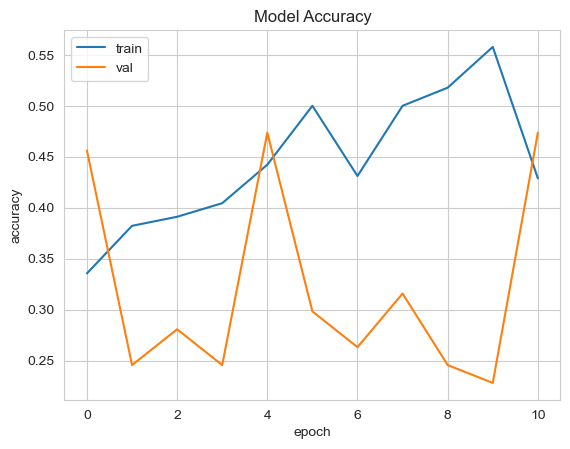

In [138]:
# Plot learning curves
import matplotlib.pyplot as plt


plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

Training was performed over a maximum of 25 epochs with early stopping to prevent overfitting, using categorical_crossentropy as the loss function and adam as the optimizer. Batch size was set to 16. Accuracy was tracked on both training and validation sets across all epochs.

The final test accuracy achieved by the model was approximately 31.6%, as shown in the evaluation output. The plotted learning curves indicated some improvement in training accuracy over time but showed high fluctuation in validation accuracy, suggesting the model struggled to generalize. This outcome is expected for an MLP working on raw image data, as such architectures typically lack the capacity to extract spatial features effectively.

### C: Human-Level Performance Accuracy

Five participants completed a survey for the human-level performance (HLP) baseline, with 50 answers collected for each class. Their individual scores were 42%, 48%, 52%, 55% and 55%.

HLP: (42 + 55 + 55 + 48 + 52) / 5 = 50.4%

## Task 3.3: Basic Convolutional Neural Network (Iteration 1)

### A: Preprocessing


In the first iteration of the model, a custom function was implemented to streamline the image loading and preprocessing process. The data was reloaded for this iteration to ensure ease of use and to avoid rerunning the entire notebook or repeating earlier preprocessing steps. The function 'load_images_and_labels' was established when loading the dataset for the MLP model. This function utilized the os module to systematically traverse the dataset’s folder structure and used cv2 (OpenCV) for efficient image loading and processing. Labels were automatically assigned based on folder names, which allowed for a structured and scalable approach.

Each image was resized to a uniform shape of 128×128 pixels and converted from OpenCV’s default BGR format to RGB to align with the input expectations of most deep learning models. The images were normalized to the [0, 1] range and stored as float32 NumPy arrays, which are well-suited for TensorFlow-based training workflows.

As the dataset was already organized by class folders, only basic label encoding was necessary. Folder names were encoded into integers using LabelEncoder, followed by one-hot encoding to match the categorical classification setup.

This preprocessing ensured that all data passed to the model was clean, consistently formatted, and ready for baseline model training.

In [249]:
# Load the dataset
X, y = load_images_and_labels('Dataset_Images/Resized images_extra')

# Print shape to confirm correctness
print("Dataset shape:", X.shape, y.shape)

Dataset shape: (564, 128, 128, 3) (564,)


In [250]:
X

In [251]:
print("Labels:", y)

In [252]:
from sklearn.preprocessing import LabelEncoder
from tensorflow import keras
# Encode labels
label_encoder = LabelEncoder()
y_integer_encoded = label_encoder.fit_transform(y)
y_onehot_encoded = keras.utils.to_categorical(y_integer_encoded, num_classes=3)

# Split the dataset into training, validation, and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y_onehot_encoded, test_size = 1/10, random_state = 0)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size = 1/9, random_state = 0)

print(X_train.shape, X_val.shape, X_test.shape)

(450, 128, 128, 3) (57, 128, 128, 3) (57, 128, 128, 3)


In [253]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (450, 128, 128, 3)
y_train shape: (450, 3)
X_val shape: (57, 128, 128, 3)
X_test shape: (57, 128, 128, 3)


### B: CNN Architecture

The architecture of the first CNN model was developed through an iterative process of trial and error, testing various configurations to achieve a balance between learning effectiveness and overfitting risk. Given the complexity of the classification task, three convolutional layers were included to allow the model to extract both low- and high-level spatial features. The depth was kept moderate, as adding more layers could potentially lead to overfitting, especially when working with a limited dataset.

Max pooling was used after each convolutional layer to progressively reduce the spatial dimensions while retaining essential features, helping control the model's complexity. To further improve generalization, a dropout layer was added before the dense layers, and BatchNormalization was applied to stabilize training and accelerate convergence by normalizing layer outputs.

The final structure of the model was also influenced by input and suggestions from a mentor, which helped refine the configuration and ensure a solid foundation for further experimentation and improvement.

In [254]:
from keras.src.layers import Dropout, BatchNormalization
from keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D

model_1 = Sequential([
    Conv2D(filters=32, kernel_size=3, activation='relu', padding='same', input_shape=(128, 128, 3)),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(filters=64, kernel_size=3, activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(filters=128, kernel_size=3, activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2, 2)),
    BatchNormalization(),
    Dropout(0.2),
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(3, activation='softmax')
])

In [255]:
model_1.summary()

Model: "sequential_27"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_27 (Conv2D)          (None, 128, 128, 32)      896       
                                                                 
 max_pooling2d_27 (MaxPooli  (None, 64, 64, 32)        0         
 ng2D)                                                           
                                                                 
 conv2d_28 (Conv2D)          (None, 64, 64, 64)        18496     
                                                                 
 max_pooling2d_28 (MaxPooli  (None, 32, 32, 64)        0         
 ng2D)                                                           
                                                                 
 conv2d_29 (Conv2D)          (None, 32, 32, 128)       73856     
                                                                 
 max_pooling2d_29 (MaxPooli  (None, 16, 16, 128)     

### C: CNN Training

The CNN model was trained using a standard supervised learning approach with categorical cross-entropy loss, suitable for multi-class classification. The Adam optimizer was selected for its efficiency and adaptive learning rate capabilities, which are well-suited for image classification tasks.

Training was conducted for up to 100 epochs, with a batch size of 32, balancing learning stability and computational efficiency. To prevent overfitting and ensure generalization, early stopping was implemented. This callback monitored the validation loss and stopped training if no improvement was observed for 7 consecutive epochs, while also restoring the best-performing model weights.

This strategy aimed to optimize performance while avoiding unnecessary training time and overfitting.

In [256]:
import tensorflow as tf

early_stopping = keras.callbacks.EarlyStopping(patience=7, restore_best_weights=True, monitor='val_loss')
model_checkpoint = tf.keras.callbacks.ModelCheckpoint('cats_and_dogs.keras', save_best_only=True, monitor='val_loss')

model_1.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])


history_1 = model_1.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=100, batch_size=32, callbacks=[early_stopping])

Epoch 1/100
15/15 [==============================] - 2s 80ms/step - loss: 1.1185 - accuracy: 0.3556 - val_loss: 1.1137 - val_accuracy: 0.2982
Epoch 2/100
15/15 [==============================] - 1s 73ms/step - loss: 1.1185 - accuracy: 0.3311 - val_loss: 1.1076 - val_accuracy: 0.2982
Epoch 3/100
15/15 [==============================] - 1s 72ms/step - loss: 1.0909 - accuracy: 0.3911 - val_loss: 1.1480 - val_accuracy: 0.2982
Epoch 4/100
15/15 [==============================] - 1s 68ms/step - loss: 1.0968 - accuracy: 0.3689 - val_loss: 1.1064 - val_accuracy: 0.2632
Epoch 5/100
15/15 [==============================] - 1s 72ms/step - loss: 1.0934 - accuracy: 0.3600 - val_loss: 1.1181 - val_accuracy: 0.2982
Epoch 6/100
15/15 [==============================] - 1s 68ms/step - loss: 1.0786 - accuracy: 0.4178 - val_loss: 1.1041 - val_accuracy: 0.3158
Epoch 7/100
15/15 [==============================] - 1s 73ms/step - loss: 1.0709 - accuracy: 0.4111 - val_loss: 1.0968 - val_accuracy: 0.2982
Epoch 

### D: Model Evaluation

To evaluate the performance of the CNN model, a combination of metrics and visual tools will be used. The primary metric will be accuracy, assessed on both the validation and test sets to measure how well the model generalizes. Additionally, training and validation loss and accuracy curves will be plotted over the epochs to observe learning trends and identify signs of overfitting. A confusion matrix will also be generated to analyze class-wise predictions, allowing for a better understanding of which face shapes are most accurately classified and where the model may be making consistent errors.

In [257]:
model_1.evaluate(X_test, y_test)

2/2 [==============================] - 0s 23ms/step - loss: 1.0954 - accuracy: 0.3684


[1.0954018831253052, 0.3684210479259491]

In [258]:
model_1.save('iter_1_res.keras')

TThe initial CNN model achieved a test accuracy of 36.8% with a loss of 1.0954. While the training accuracy showed a steady upward trend, the validation accuracy was highly erratic and failed to show consistent improvement, suggesting possible overfitting and sensitivity to data variability.

Despite applying dropout and data augmentation, the gap between training and validation loss widened in later epochs. This indicates that the model learned patterns specific to the training data that did not generalize well to new samples.

The confusion matrix reveals a strong bias toward predicting Class 0 across all true labels. Classes 1 and 2 were frequently misclassified as Class 0, showing that the model has difficulty distinguishing between overlapping features or is affected by class imbalance.

Overall, the CNN architecture shows more learning capacity compared to simpler models.

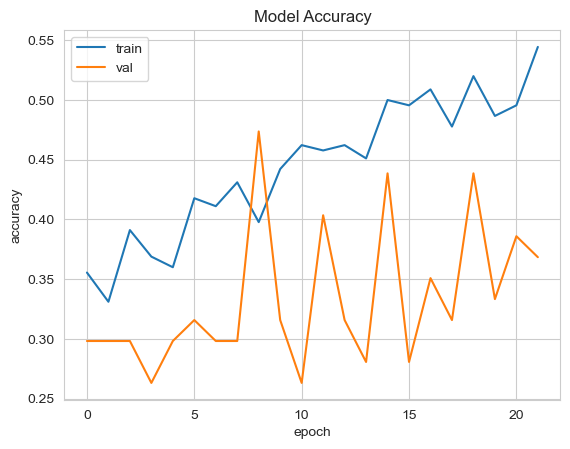

In [259]:
# Plot learning curves
import matplotlib.pyplot as plt


plt.plot(history_1.history['accuracy'])
plt.plot(history_1.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

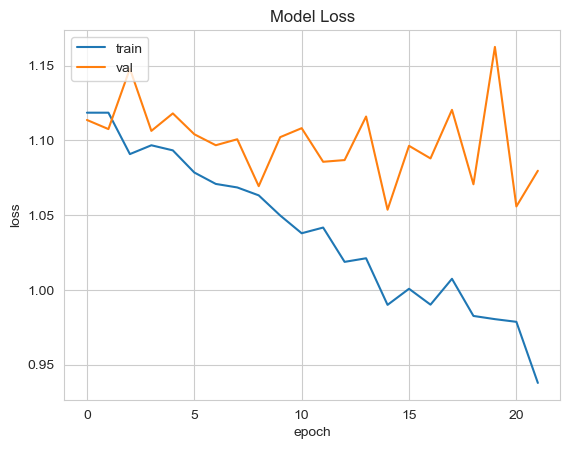

In [260]:
# Plot loss curves
plt.plot(history_1.history['loss'])
plt.plot(history_1.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()


2/2 [==============================] - 0s 38ms/step


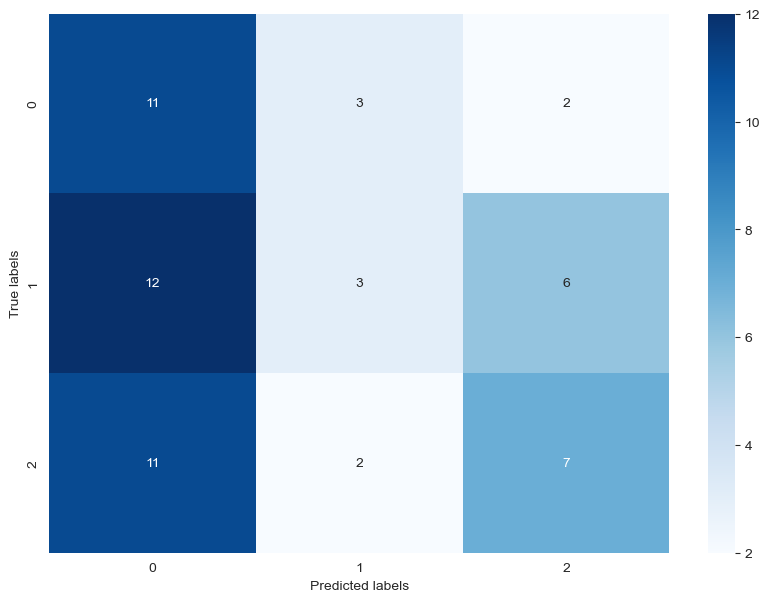

In [261]:
# Plotting a confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_pred = model_1.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_test_classes, y_pred_classes)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.show()

## Task 3.4: Data Augmentation (Iteration 2)

### A: Preprocessing

In this iteration, data augmentation was introduced to improve the generalization of the model and reduce the risk of overfitting. Before applying augmentation during training, a few cells were included to visualize the transformations and ensure that they preserved the essential features of the face. This helped confirm that the augmented data remained suitable for the task.

Several data augmentation techniques were tested during development, including flipping, translation, contrast adjustments, and more. However, most of these were ultimately excluded. Since the intended users of the tool are expected to take face-centered photos while looking directly at the camera, many of these transformations would not only be unnecessary but could negatively impact model performance. In fact, without those conditions (frontal orientation and a centered face), accurate face shape recognition becomes difficult, if not impossible.

As a result, only minimal and controlled augmentations such as random zoom and slight rotation were kept, as they mimic natural variations in camera position while still maintaining the structure needed to accurately identify face shape. The augmentation layer was placed at the start of the CNN model and applied only during training, leaving the validation and test sets untouched for fair evaluation. Further preprocessing was not needed, as the dataset had already been resized and normalized in earlier steps.

In [187]:
X, y = load_images_and_labels('Dataset_Images/Resized images_extra')

print("Dataset shape:", X.shape, y.shape)

Dataset shape: (564, 128, 128, 3) (564,)


In [188]:
X

In [3]:
import matplotlib.pyplot as plt

# Display a single image (the first one in the dataset)
plt.figure(figsize=(4, 4))
plt.imshow(X[0])
plt.axis('off')
plt.show()

In [190]:
# Encode labels
label_encoder = LabelEncoder()
y_integer_encoded = label_encoder.fit_transform(y)
y_onehot_encoded = keras.utils.to_categorical(y_integer_encoded, num_classes=3)

# Split the dataset into training, validation, and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y_onehot_encoded, test_size = 1/10, random_state = 0)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size = 1/9, random_state = 0)

print(X_train.shape, X_val.shape, X_test.shape)

(450, 128, 128, 3) (57, 128, 128, 3) (57, 128, 128, 3)


In [178]:
import keras
from keras import layers
from keras.models import Sequential
from keras.optimizers import Adam
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
import numpy as np
import skimage.io as ski_io
import skimage.util as ski_util

# Create the preprocessing layer for data augmentation
data_augmentation = keras.Sequential([
    layers.RandomZoom(0.2),
    layers.RandomRotation(0.05),
])

In [179]:
import skimage as ski
import numpy as np

# Iterate over all images in X_train
for image in X_train:
    # Convert the image to a floating-point image
    image = ski.util.img_as_float(image)

    # Reshape the image because the preprocessing layer expects an array of images
    image = np.reshape(image, (1,) + image.shape)

    augmented_images = []
    num_images = 5
    for _ in range(num_images):
        # Generate an augmented image
        augmented = data_augmentation(image)
        augmented_images.append(augmented[0])

In [180]:
import math
import matplotlib.pyplot as plt

# Number of augmented images
num_images = len(augmented_images)
grid_size = int(math.ceil(math.sqrt(num_images)))

fig, axes = plt.subplots(nrows=grid_size, ncols=grid_size, figsize=(10, 10))
axes = axes.flatten()

for i in range(num_images):
    # Clip pixel values to the valid range [0, 1]
    image = np.clip(augmented_images[i], 0, 1)
    axes[i].imshow(image)
    axes[i].axis('off')

# Hide any unused subplots
for i in range(num_images, grid_size * grid_size):
    axes[i].axis('off')

plt.tight_layout()
plt.show()

### B: CNN Architecture

The architecture used in this iteration is based on the same structure as the previously developed basic CNN model. The addition of data augmentation was integrated as the first layer of the model using Keras’ Sequential API. Controlled transformations such as random zoom and random rotation were applied during training to introduce natural variations and improve generalization. These augmentations simulate slight camera movement or head tilt, which are expected in real-world user input. By placing this augmentation directly into the model, the transformations are applied dynamically during training while leaving validation and test data unchanged. This adjustment allowed the model to train on more diverse data without modifying the core architectur

In [11]:
# Add your code to create a CNN architecture for your image dataset.

# CNN Architecture
from keras.src.layers import Dropout, BatchNormalization
from keras.layers import Conv2D, MaxPooling2D
import keras
from keras import layers
from keras.models import Sequential
from keras.optimizers import Adam
from keras.layers import Flatten, Dense, Dropout, GlobalAveragePooling2D
import numpy as np


# Create the preprocessing layer for data augmentation
data_augmentation = keras.Sequential([
    layers.RandomZoom(0.2),
    layers.RandomRotation(0.05),
])

# Define the CNN model
model_2 = Sequential([
    data_augmentation,
    Conv2D(filters=32, kernel_size=3, activation='relu', padding='same', input_shape=(128, 128, 3)),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(filters=64, kernel_size=3, activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(filters=128, kernel_size=3, activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2, 2)),
    BatchNormalization(),
    Dropout(0.2),
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(3, activation='softmax')
])


### C: CNN Training

The strategy follows a structure consistent with previous iteration. The model will again be compiled with categorical cross-entropy as the loss function, and accuracy as the evaluation metric. Early stopping will be implemented to monitor validation loss, with the patience parameter defined during the training process. The model is trained and validated using the extracted output features from the pretrained MobileNet base.

In [192]:
# Add your code to train the CNN model using proper loss functions, optimizers, and hyperparameters.

# Train the model
early_stopping = keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True, monitor='val_loss')

model_2.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

history_2 = model_2.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=100, batch_size=32, callbacks=[early_stopping])

### D: Model Evaluation

To evaluate the performance of the CNN model, a combination of metrics and visual tools will be used. The primary metric will be accuracy, assessed on both the validation and test sets to measure how well the model generalizes. Additionally, training and validation loss and accuracy curves will be plotted over the epochs to observe learning trends and identify signs of overfitting. A confusion matrix will also be generated to analyze class-wise predictions, allowing for a better understanding of which face shapes are most accurately classified and where the model may be making consistent errors.

In [193]:
# Add your code to evaluate the CNN model using appropriate metrics and learning curves.
# Evaluate the model
model_2.evaluate(X_test, y_test)

2/2 [==============================] - 0s 32ms/step - loss: 1.2104 - accuracy: 0.3509


[1.210362434387207, 0.35087719559669495]

The model trained with data augmentation achieved a test accuracy of 35.1% and a loss of 1.2104. While the training accuracy improved consistently across epochs, the validation accuracy remained volatile and relatively low. This inconsistency suggests that while the model learned from the augmented data, it failed to generalize effectively to the validation set.

A clearer indication of overfitting is seen in the loss curves. The training loss steadily decreased, while the validation loss fluctuated and rose significantly towards the end. This points to the model fitting too closely to the augmented training data without gaining transferable insights.

The confusion matrix highlights a major issue with prediction balance. Class 0 was heavily favored across all predictions, with Classes 1 and 2 frequently misclassified as Class 0. This misclassification pattern could suggest that data augmentation may have introduced noise or distortions that emphasized certain dominant features at the expense of others.

Overall, these results indicate that while data augmentation increased variability in the training set, it did not lead to meaningful performance gains. Probably because the data augmentation did not reflect any realistic input scenarios.

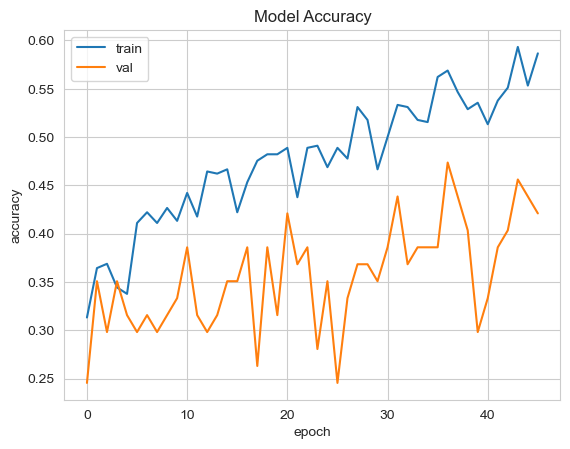

In [194]:
# Plot learning curves
import matplotlib.pyplot as plt


plt.plot(history_2.history['accuracy'])
plt.plot(history_2.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

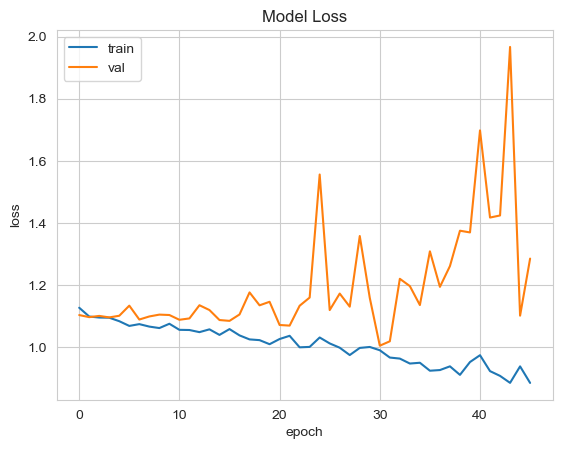

In [195]:
# Plot loss curves
plt.plot(history_2.history['loss'])
plt.plot(history_2.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()


2/2 [==============================] - 0s 25ms/step


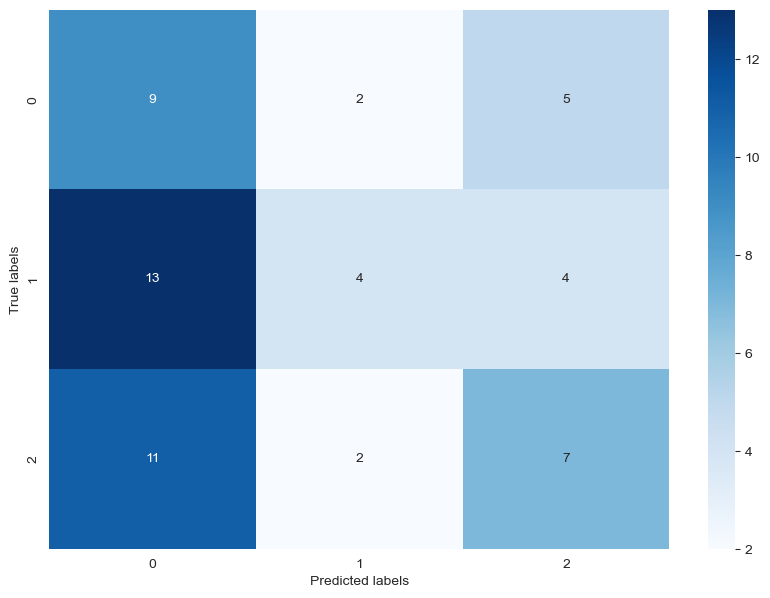

In [196]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns

y_pred = model_2.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_test_classes, y_pred_classes)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.show()

## Task 3.5: Transfer Learning (Iteration 3)

### A: Preprocessing

In this iteration, the dataset was once again reloaded using the previously defined image-loading function. This ensured consistency in image size (128×128) and other characteristics, which are compatible with the input requirements of the MobileNet architecture used for transfer learning.

After splitting the dataset into training, validation, and test sets, the images were preprocessed using mobilenet.preprocess_input(). This step was essential because MobileNet expects inputs to be with pixel values scaled to the range [-1, 1], as it was originally trained on ImageNet data. Preprocessing in this way ensures that the input images are aligned with the model's expected distribution, allowing it to extract meaningful features effectively.

In [212]:
import cv2
import numpy as np
import os

X, y = load_images_and_labels('Dataset_Images/Resized images_extra')

print("Dataset shape:", X.shape, y.shape)

Dataset shape: (564, 128, 128, 3) (564,)


In [213]:
X

In [214]:
from sklearn.preprocessing import LabelEncoder
import keras

# Encode labels
label_encoder = LabelEncoder()
y_integer_encoded = label_encoder.fit_transform(y)
y_onehot_encoded = keras.utils.to_categorical(y_integer_encoded, num_classes=3)

In [215]:
y_onehot_encoded

array([[1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.],
       ...,
       [0., 0., 1.],
       [0., 0., 1.],
       [0., 0., 1.]], dtype=float32)

In [12]:
import matplotlib.pyplot as plt

# Display a single image (the first one in the dataset)
plt.figure(figsize=(4, 4))
plt.imshow(X[0])
plt.axis('off')
plt.show()

In [217]:
# Split the dataset into training, validation, and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y_onehot_encoded, test_size = 1/10, random_state = 0)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size = 1/9, random_state = 0)

print(X_train.shape, X_val.shape, X_test.shape)

# Preprocess images for MobileNet
X_train_mobilenet = keras.applications.mobilenet.preprocess_input(X_train * 255)
X_val_mobilenet = keras.applications.mobilenet.preprocess_input(X_val * 255)
X_test_mobilenet = keras.applications.mobilenet.preprocess_input(X_test * 255)

(450, 128, 128, 3) (57, 128, 128, 3) (57, 128, 128, 3)


In [218]:
X_train_mobilenet

### B: CNN Architecture

MobileNet was selected as the initial model for transfer learning, based on university recommendations. The approach involved following the provided guidelines while making adjustments where necessary to suit the structure of the dataset. The images were already formatted at 128×128 resolution, which matched MobileNet’s input requirements and allowed for direct integration without additional resizing.

A GlobalAveragePooling2D layer was used in place of a Flatten() layer to reduce the output from the base model. Using Flatten() would have produced a high-dimensional vector, increasing the model’s complexity and the likelihood of overfitting. Global average pooling helped maintain a lower parameter count while preserving essential feature information for classification.

In [219]:
from tensorflow import keras

base_model = keras.applications.MobileNet(
                include_top=False,
                weights='imagenet',
                input_shape=(128, 128, 3))
base_model.trainable = False
base_model.summary()


In [220]:
# Extract features
output_features_train = base_model.predict(X_train_mobilenet)
output_features_val = base_model.predict(X_val_mobilenet)
output_features_test = base_model.predict(X_test_mobilenet)

2/2 [==============================] - 0s 48ms/step


In [221]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, GlobalAveragePooling2D

dense_model_1 = Sequential([
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(3, activation='softmax')
])

### C: CNN Training

The strategy follows a structure consistent with previous iterations. Based on the provided guidelines, the learning rate will be set to 1e-5, using the Adam optimizer. The model will be compiled with categorical cross-entropy as the loss function, and accuracy as the evaluation metric. Early stopping will be implemented to monitor validation loss, with the patience parameter defined during the training process. The model will be trained and validated using the extracted output features from the pretrained MobileNet base.

In [222]:
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping

adam_optimizer = Adam(learning_rate=1e-5)

dense_model_1.compile(optimizer=adam_optimizer,
                    loss='categorical_crossentropy',
                    metrics=['accuracy'])
callback = EarlyStopping(monitor='val_loss',
                        patience=5,
                        restore_best_weights=True)
H = dense_model_1.fit(output_features_train,
                y_train,
                batch_size=32,
                epochs=100,
                validation_data = (output_features_val, y_val),
                callbacks=[callback])

### D: Model Evaluation

To evaluate the performance of the CNN model, a combination of metrics and visual tools will be used. The primary metric will be accuracy, assessed on both the validation and test sets to measure how well the model generalizes. Additionally, training and validation loss and accuracy curves will be plotted over the epochs to observe learning trends and identify signs of overfitting. A confusion matrix will also be generated to analyze class-wise predictions, allowing for a better understanding of which face shapes are most accurately classified and where the model may be making consistent errors.

In [223]:
# Evaluate the model
dense_model_1.evaluate(output_features_test, y_test)

2/2 [==============================] - 0s 4ms/step - loss: 1.0725 - accuracy: 0.4211


[1.0724653005599976, 0.42105263471603394]

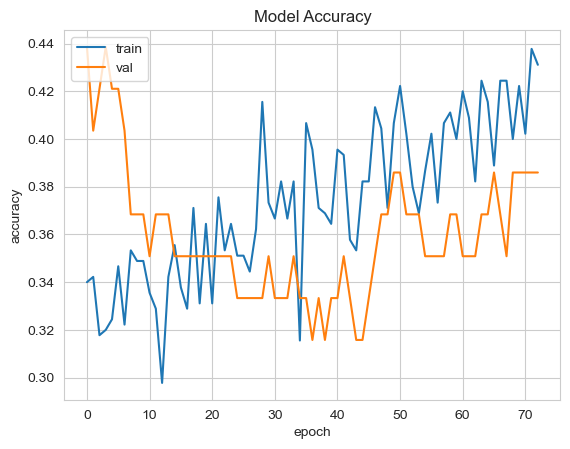

In [224]:
# Plot learning curves
import matplotlib.pyplot as plt


plt.plot(H.history['accuracy'])
plt.plot(H.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

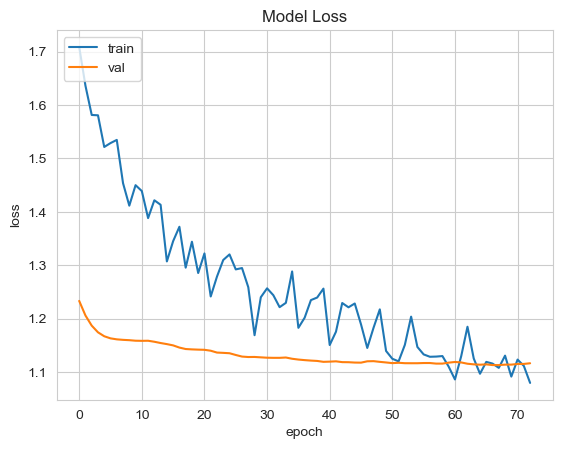

In [225]:
# Plot loss curves

plt.plot(H.history['loss'])
plt.plot(H.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

2/2 [==============================] - 0s 4ms/step


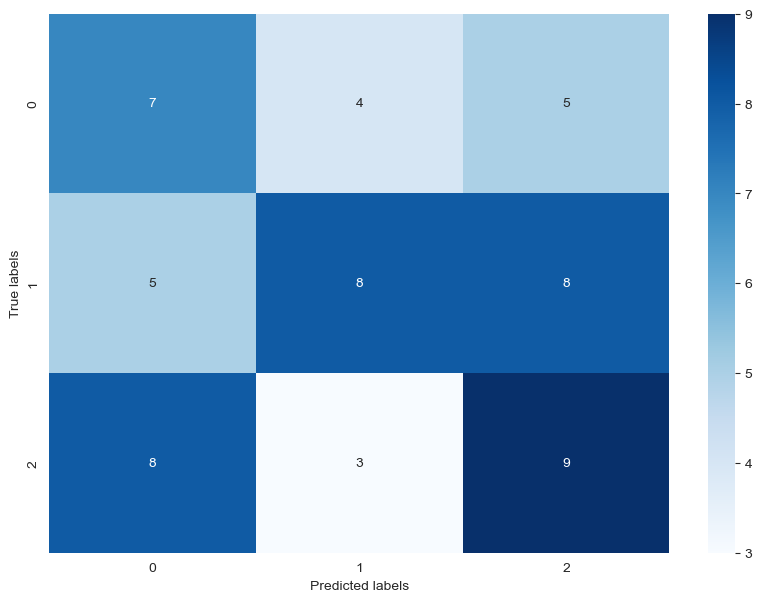

In [226]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_pred = dense_model_1.predict(output_features_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_test_classes, y_pred_classes)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.show()

The final model achieved a test accuracy of 42.1% with a loss of 1.0725. While training accuracy gradually increased, the validation accuracy fluctuated significantly and remained relatively low, which again suggests the model struggled to generalize beyond the training data.

Although the training and validation losses steadily declined throughout the epochs, the validation accuracy did not follow the same upward trend. This indicates that the model may have been learning features that reduced loss but did not effectively support accurate predictions on unseen data.

The confusion matrix shows considerable misclassification across all classes. For example, instances from Class 0 were frequently misclassified as Class 2, and vice versa. Class 1 was predicted more consistently but still showed frequent confusion with both other classes. This pattern may point to overlapping visual features between face shape categories, as well as possible imbalance or ambiguity in the dataset. It reinforces the need for more distinct training samples and possibly a better class separation strategy.

## Task 3.6: Model Improvement (Iteration 4)


## Transfer Learning with VGG16

### A: Preprocessing


In this iteration, the dataset was once again reloaded using the previously defined image-loading function. The preprocessing steps were simialar to the ones for MobileNet except the images were preprocessed using vgg16.preprocess_input(), multiplied by 255 again to ensure that the input images are aligned with the model's expected distribution, allowing it to extract meaningful features effectively.

In [64]:
#Importing libraries
import keras, os
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPool2D, Flatten
from keras.preprocessing.image import ImageDataGenerator
import numpy as np
from keras.applications.vgg16 import VGG16

In [65]:
# Load the dataset
X, y = load_images_and_labels('Dataset_Images/Resized images_extra')

# Encode labels
label_encoder = LabelEncoder()
y_integer_encoded = label_encoder.fit_transform(y)
y_onehot_encoded = keras.utils.to_categorical(y_integer_encoded, num_classes=3)

In [66]:
# Split the dataset into training, validation, and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y_onehot_encoded, test_size = 1/10, random_state = 0)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size = 1/9, random_state = 0)

# Preprocess the images for VGG16
X_train_vgg16 = keras.applications.vgg16.preprocess_input(X_train * 255)
X_val_vgg16 = keras.applications.vgg16.preprocess_input(X_val * 255)
X_test_vgg16 = keras.applications.vgg16.preprocess_input(X_test * 255)

X_train_vgg16

### B: CNN Architecture


The architecture for this iteration is based on the structure previously applied with MobileNet. A similar model composition is used, where a pretrained base model is followed by custom classification layers. Any further architectural adjustments will be determined based on training performance.

The VGG16 base model is loaded with include_top=False to exclude its original classification head, as the task requires a custom output layer for three classes. The argument weights='imagenet' ensures that the model initializes with pretrained weights, leveraging feature representations learned from a large-scale dataset. The base model is frozen (trainable = False) to retain these pretrained features and prevent them from being updated during training, allowing only the newly added dense layers to learn task-specific patterns. This setup enables efficient transfer learning while minimizing the risk of overfitting.

In [67]:
# Load the VGG16 model without the top layers
base_model = VGG16(include_top=False, weights='imagenet', input_shape=(128, 128, 3))
base_model.trainable = False

# Define the dense model
dense_model = Sequential()
dense_model.add(base_model)
dense_model.add(GlobalAveragePooling2D())
dense_model.add(Dense(128, activation='relu'))
dense_model.add(Dense(64, activation='relu'))
dense_model.add(Dropout(rate=0.5))
dense_model.add(Dense(3, activation='softmax'))

### C: CNN Training

The strategy follows a structure consistent with previous iterations. Based on the provided guidelines, the learning rate will again be set to 1e-5, using the Adam optimizer. The model will be compiled with categorical cross-entropy as the loss function, and accuracy as the evaluation metric. Early stopping will be implemented to monitor validation loss, with the patience parameter defined during the training process. The model will be trained and validated using the extracted output features from the pretrained MobileNet base.

In [68]:
# Compile the dense model
adam_optimizer = Adam(learning_rate=1e-5)
dense_model.compile(optimizer=adam_optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

In [69]:
# Define early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Train the dense model
history = dense_model.fit(
    X_train_vgg16, y_train,
    validation_data=(X_val_vgg16, y_val),
    epochs=250,
    batch_size=32,
    callbacks=[early_stopping]
)

### D: Model Evaluation

To evaluate the performance of the CNN model, a combination of metrics and visual tools will be used. The primary metric will be accuracy, assessed on both the validation and test sets to measure how well the model generalizes. Additionally, training and validation loss and accuracy curves will be plotted over the epochs to observe learning trends and identify signs of overfitting. A confusion matrix will also be generated to analyze class-wise predictions, allowing for a better understanding of which face shapes are most accurately classified and where the model may be making consistent errors.

In [70]:
dense_model.evaluate(X_test_vgg16, y_test)

2/2 [==============================] - 1s 400ms/step - loss: 1.3590 - accuracy: 0.4386


[1.3590266704559326, 0.4385964870452881]

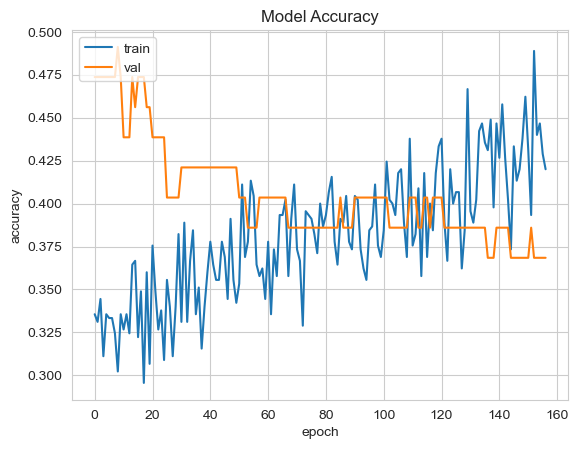

In [71]:
# Plot learning curves
import matplotlib.pyplot as plt


plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

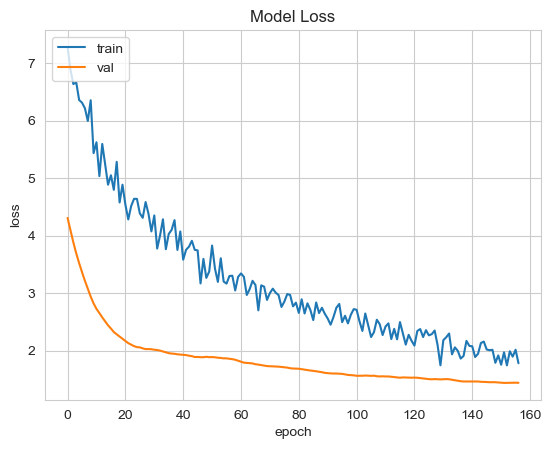

In [72]:
# Plot loss curves

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

2/2 [==============================] - 1s 431ms/step


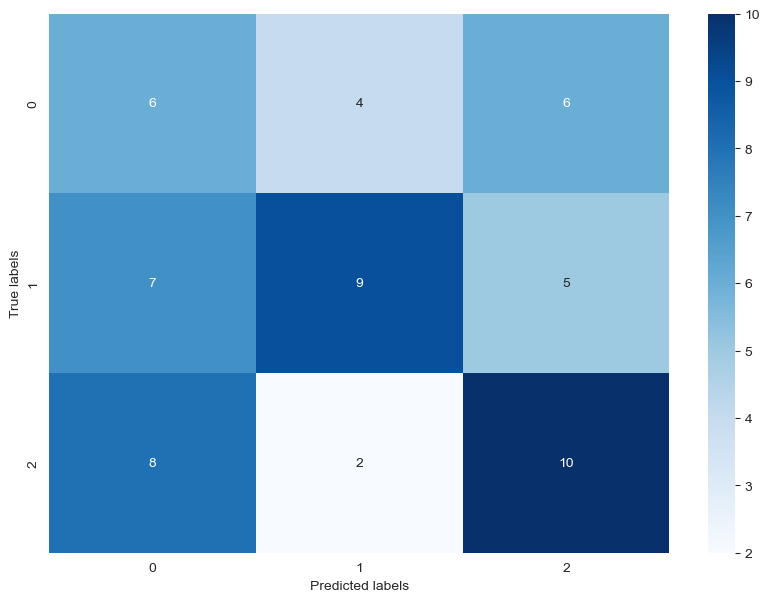

In [73]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns

y_pred = dense_model.predict(X_test_vgg16)
y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_test_classes, y_pred_classes)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.show()

The final model achieved a test accuracy of 43.9% with a loss of 1.36. The accuracy plots indicate that both training and validation accuracies progressed slowly and hovered just below the 50% threshold across 160 epochs. The curves did not diverge significantly, suggesting the model did not strongly overfit the training data. However, neither curve exhibited sharp improvements, implying limited success in learning distinct class-specific features.

The loss graphs show a consistent downward trend for both training and validation sets, reflecting a gradual reduction in prediction error. Despite this, the flat accuracy lines suggest that the model's increased confidence may have been misaligned, possibly reinforcing incorrect predictions.

The confusion matrix reveals a relatively even distribution of predictions across the three classes. Each class had several correctly identified samples, but also notable misclassifications, particularly between Classes 0 and 2, and some overlap with Class 1. These results demonstrate modest improvement in prediction balance, but also indicate that class confusion remains an issue.

Overall, the model shows progress over earlier iterations, especially in maintaining generalization across the dataset. However, the plateaued accuracy signals that further refinement is needed, potentially through improved data preprocessing or enhanced feature extraction strategies.

## Task 3.7: Error Analysis

### A: Wrong Classifications

In [76]:
misclassified_idx = np.where(y_pred_classes != y_test_classes)[0]
misclassified_images = X_test[misclassified_idx]
misclassified_labels = y_test_classes[misclassified_idx]

# Calculate grid dimensions based on number of misclassified images
n_images = len(misclassified_idx)
n_cols = 5
n_rows = (n_images // n_cols) + (1 if n_images % n_cols > 0 else 0)

# Create appropriately sized figure
plt.figure(figsize=(n_cols * 4, n_rows * 3))

# Plot all misclassified images
for i, idx in enumerate(misclassified_idx):
    plt.subplot(n_rows, n_cols, i + 1)
    plt.imshow(X_test[idx])
    plt.title(f'True: {y_test_classes[idx]}\nPred: {y_pred_classes[idx]}', fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

### B: Identify Error Types

Inter-Class Similarity was one of the most prevalent issues. A number of misclassifications occurred when faces labeled as “Round” or “Heart” were predicted as “Square,” and vice versa. These errors appear to result from overlapping visual characteristics between face shape categories. For instance, softly defined jawlines, wide cheeks, or tapered chins may create ambiguous profiles that share traits across classes, making it difficult for the model to assign the correct label.

Visual Obstruction and Contextual Misunderstandings also contributed to misclassification. In multiple examples, individuals wore heavy makeup or had voluminous hairstyles that altered the perceived structure of their faces. These elements either obscured key facial landmarks or introduced false visual cues, such as shadows or highlights, that misled the model. In some cases, accessories like earrings or glasses and shadows from hair covered parts of the cheek or jawline, limiting the model's ability to identify essential geometric cues.

Pose and Orientation Variability was another factor. Several images showed subjects with tilted heads, asymmetric expressions such as wide smiles and tilted eyebrows, or turned faces. These angles distorted facial proportions or altered the model’s ability to interpret jaw curvature and cheekbone prominence, which are crucial for determining face shape.

Facial Expression Bias further impacted predictions. Wide smiles or raised eyebrows modified the contours of the face, temporarily exaggerating or minimizing features such as cheekbones or chin width. These subtle but significant alterations can lead to classification errors, especially if the training set lacks varied emotional expressions.

Lighting and Exposure Issues were evident in some misclassified cases. Faces with harsh lighting, deep shadows, or washed-out features presented less contrast, making structural lines harder to detect. In other examples, excessive smoothing or editing reduced the visibility of key features, affecting model interpretation.

Image Quality and Noise also played a role. A few images appeared lower in resolution or slightly blurred, which limited the clarity of facial geometry and reduced the model’s ability to make fine distinctions.

These patterns highlight the model’s sensitivity to subtle variations and suggest that improvements in dataset diversity, preprocessing, and training augmentation could help reduce such misclassifications. Addressing these challenges may lead to a more robust and reliable face shape classifier.


### C: Categorize Errors

Since some images apply to a few of the established categories the total number of images I divide by is 66.
- Inter Class similarity:	19 images -> 28.8%

- Visual Obstruction and Contextual Misunderstandings: 10 -> 15.2%

- Pose and Orientation Variability:	17 -> 25.8%

- Facial Expression Bias:	9 -> 13.6%

- Lighting and Exposure Issues: 5 -> 7.6%

- Image Quality and Noise: 6 -> 9.1%


### D: Propose Improvements

1. Inter-Class Similarity (28.8%)
The largest share of misclassifications stems from visual overlap between categories, particularly when features such as jaw shape, face length, and cheek prominence are subtle or shared between multiple face shapes. The model likely lacks a nuanced internal representation of shape-defining boundaries and may generalize features too broadly.

2. Pose and Orientation Variability (25.8%)
A significant portion of errors occurred in images with non-frontal facial angles. This suggests that the model struggles to adapt to slight deviations from frontal orientation, likely due to that the model is not capable of recognizing the underlying face shape from angled or turned poses, as the geometry of the face is altered and certain features become partially hidden or visually distorted.

3. Visual Obstruction and Contextual Misunderstandings (15.2%)
Obstructions like large hairstyles, glasses, or earrings obscure key regions (e.g., jawlines or temples), making it harder for the model to read geometric features accurately. The model may also be distracted by context (accessories), which it mistakenly incorporates into predictions.

4. Facial Expression Bias (13.6%)
Expressions like smiling, eyebrow movement, or raised cheeks alter the appearance of facial structure. These transient features may lead the model to overfit on emotion-related visual cues rather than permanent shape indicators.

5. Image Quality and Noise (9.1%)
Blurry, pixelated, or over-smoothed images obscure the crisp lines and edges necessary for determining face shape. The model is likely not robust against such degradation in input quality.

6. Lighting and Exposure Issues (7.6%)
Inadequate lighting flattens features or casts misleading shadows, which can distort model perception. Uneven light exposure especially affects facial symmetry and outline clarity.

Based on the error analysis, several improvements can be considered to enhance the model’s performance. While data augmentation techniques were previously applied, they did not significantly improve accuracy. This suggests that instead of broadly augmenting the dataset, it may be more beneficial to focus on curating a dataset centered around front-facing images with diverse lighting conditions. Ensuring consistent facial orientation while maintaining exposure to varying brightness and contrast would help the model learn to distinguish features without being affected by pose or lighting inconsistencies.

Additionally, integrating landmark-based preprocessing could greatly improve classification accuracy. By detecting and isolating facial landmarks (such as the jawline, cheekbones and forehead), the model can prioritize shape-related geometry and reduce its reliance on surrounding context, which often leads to misclassification. This targeted approach can help the model become more sensitive to the structural differences that define face shapes.

Another recommended enhancement is expression normalization and face alignment. Standardizing all inputs by aligning faces to a common orientation and minimizing facial expression variability can help the model better recognize fixed anatomical features. Tools such as generative models could assist in smoothing out expressions, ensuring that key features like jaw curvature or cheekbone prominence remain clearly defined across examples.

Together, these improvements aim to address the most frequent sources of error and help the model develop a stronger and more consistent understanding of facial geometry across varied but controlled conditions.